##### **Import Libary and Dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd




palette = sns.color_palette("Set2")
sns.set_palette(palette)

print("Everything works")

Everything works


In [2]:
survey = pd.read_csv("mh_new.csv")

print("done")

done


##### **Cleaning Data**

In [3]:
survey.head(20)

,UserID,SurveyID,Age,Gender,Country_of_Residence,Employment_country,self_employed,company_size,tech_company,tech_role,Suspected_conditions,Diagonsed_conditions,Diagonsed
0,4218,2019,24,Female,United States of America,United States of America,0,More than 1000,1,1.0,NaN,NaN,Yes
1,4217,2019,30,female,India,India,0,More than 1000,1,1.0,NaN,NaN,-1
2,4216,2019,50,Male,India,India,1,-1,-1,-1.0,NaN,NaN,-1
3,4215,2019,48,Male,United States of America,United States of America,1,-1,-1,-1.0,NaN,NaN,-1
4,4214,2019,27,male,India,India,0,More than 1000,0,1.0,NaN,NaN,-1
5,4213,2019,31,female,United States of America,United States of America,0,6-25,1,1.0,NaN,NaN,-1
6,4212,2019,26,Female,Brazil,Brazil,0,26-100,1,1.0,NaN,NaN,-1
7,4211,2019,42,Female,United States of America,United States of America,0,100-500,1,1.0,NaN,NaN,Yes
8,4210,2019,27,Male,United States of America,United States of America,1,-1,-1,-1.0,NaN,NaN,Yes
9,4209,2019,30,Male,New Zealand,New Zealand,0,26-100,1,1.0,NaN,NaN,Yes


##### Duplicates 

In [4]:
survey.duplicated().value_counts()

False    4218
Name: count, dtype: int64

##### Null Values 

In [5]:
# Check for Null Values 
#survey.isnull().sum()
null_values = (survey.isnull().sum()/len(survey))*100
print(null_values)

UserID                   0.000000
SurveyID                 0.000000
Age                      0.000000
Gender                   0.071124
Country_of_Residence     0.000000
Employment_country      29.871977
self_employed            0.000000
company_size             0.000000
tech_company             0.000000
tech_role               29.871977
Suspected_conditions    66.026553
Diagonsed_conditions    66.026553
Diagonsed               29.871977
dtype: float64


In [6]:
columns_to_clean = ["Diagonsed_conditions", "Suspected_conditions","Country_of_Residence", "Employment_country" , "Gender"]
survey[columns_to_clean] = survey[columns_to_clean].replace(r"^\s*-1\s*$", "Unknown" , regex=True)
survey[columns_to_clean] = survey[columns_to_clean] .fillna("unknown")

In [7]:
null_values = (survey.isnull().sum()/len(survey))*100
print(null_values)

UserID                   0.000000
SurveyID                 0.000000
Age                      0.000000
Gender                   0.000000
Country_of_Residence     0.000000
Employment_country       0.000000
self_employed            0.000000
company_size             0.000000
tech_company             0.000000
tech_role               29.871977
Suspected_conditions     0.000000
Diagonsed_conditions     0.000000
Diagonsed               29.871977
dtype: float64


In [8]:
# cleaning null columns with integers - to match maybe values
int_columns = ["tech_role","Diagonsed"]
survey[int_columns] = survey[int_columns].fillna('-1')

*According to OSMI (https://www.researchgate.net/publication/366737538_Predicting_mental_illness_at_workplace_using_machine_learning) −1 is not a universal answer option printed on the OSMI questionnaire. It is a numerical code used by researchers to represent certain valid answers. Its meaning must be interpreted using the answer choices for the particular question.
This has caused for the response with -1 to be omitted in the analysis of DS .*

Some columns were cleaned to align DS with appropriate data type for analysis. These Included ;

1.Age,
2.Gender,
3.Diagonsed_conditions,
4.Suspected_conditions,
5.company_size,
6.Country_of_Residence,
7.Employment_country

Response coding: For Questions 9 (Tech companies) and 13 (Tech Roles) and 5 (Self employed), 
1 represents Yes and 0 represents No. 
The original numerical values have been retained.

In [9]:
# Gender cleaning 

# create map 
gender_map = {
    "Male": ["Male", "male", "MALE", "Male-ish",
        "Guy (-ish) ^_^", "Cishet male",
        "Masculine", "masculino", "SWM",
        "something kinda male?",
        "ostensibly male, unsure what that really means",
        "Ostensibly Male",
        "male leaning androgynous",
        "male 9:1 female, roughly",
        "Male (trans, FtM)",
        "Trans man",
        "Demiguy"
        ],

    "Female": ["Female", "female", "Female (trans)",
        "Trans woman", "trans woman",
        "Transgender woman", "Trans female",
        "Trans-female", "mtf", "Transitioned, M2F",
        "Female assigned at birth",
        "Female-ish", "Female-identified",
        "Woman-identified", "femmina",
        "genderqueer woman",
        "gender non-conforming woman"
        ],

    "Non-binary": ["Nonbinary",
        "nonbinary",
        "non-binary",
        "Non-binary",
        "Non binary",
        "non binary",
        "Enby",
        "NB",
        "Genderqueer/non-binary",
        "Female/gender non-binary.",
        "Trans non-binary/genderfluid",
        "Non-binary and gender fluid"
        ],
    "Gender diverse" : ["Genderqueer",
        "genderqueer",
        "Agender",
        "agender",
        "Genderfluid",
        "genderfluid",
        "Genderfluid (born female)",
        "Genderqueer demigirl",
        "Genderflux demi-girl",
        "Bigender",
        "Androgyne",
        "Androgynous",
        "Neuter",
        "Fluid",
        "fluid",
        "Demiguy",
        "Transfeminine",
        "Other/Transfeminine",
        "Agender/genderfluid",
        "nb masculine",
        "Male/genderqueer",
        "male/androgynous",
        "Nonbinary/femme",
        "Trans non-binary/genderfluid",
        "uhhhhhhh fem genderqueer?",
        "genderqueer woman",
        "Trans non-binary/genderfluid",
        "queer",
        "Queer",
        "Questioning",
        "sometimes"
        ],

    "Other / Self-described": [
        "Other", "All", "Human", "human",
        "Unicorn", "I am a Wookie",
        "God King of the Valajar",
        "Contextual", "A little about you",
        "I have a penis", "none of your business",
        "female-bodied; no feelings about gender",
        "Male (or female, or both)",
        "male 9:1 female, roughly",
        "uhhhhhhhh fem genderqueer?",
        "Male/genderqueer",
        "A little about you"
        ],

    "Unknown": [
        "-1", "Nah", "none", "p", "rr",
        "43", "\\-", "fm"
    ]
    
}

# Create an empty dictionary
gender_lookup = {}

# Loop through your existing gender_map dictionary
for category, responses in gender_map.items():
    for response in responses:
        gender_lookup[response] = category

# Apply the mapping to your NEW Gender column
survey["Gender_Category"] = survey["Gender"].map(gender_lookup)

# Drop rows with null values in Gender_Category
survey = survey.dropna(subset=["Gender_Category"])

# Drop the old Gender column
survey = survey.drop(columns=["Gender"])
# Check the final category counts
print(survey["Gender_Category"].value_counts(dropna=False))



Gender_Category
Male                      3057
Female                    1040
Gender diverse              37
Non-binary                  27
Other / Self-described      16
Unknown                      7
Name: count, dtype: int64


In [10]:
# Rename gender_category to Gender
survey = survey.rename(columns = {"Gender_Category": "Gender"})

In [11]:
# Cleaning country of residence 
survey["Country_of_Residence"].replace({"United States": "United States of America"})


0       United States of America
1                          India
2                          India
3       United States of America
4                          India
                  ...           
4213    United States of America
4214              United Kingdom
4215                      Canada
4216    United States of America
4217    United States of America
Name: Country_of_Residence, Length: 4184, dtype: str

In [12]:
survey.head(4200)

,UserID,SurveyID,Age,Country_of_Residence,Employment_country,self_employed,company_size,tech_company,tech_role,Suspected_conditions,Diagonsed_conditions,Diagonsed,Gender
0,4218,2019,24,United States of America,United States of America,0,More than 1000,1,1.0,unknown,unknown,Yes,Female
1,4217,2019,30,India,India,0,More than 1000,1,1.0,unknown,unknown,-1,Female
2,4216,2019,50,India,India,1,-1,-1,-1.0,unknown,unknown,-1,Male
3,4215,2019,48,United States of America,United States of America,1,-1,-1,-1.0,unknown,unknown,-1,Male
4,4214,2019,27,India,India,0,More than 1000,0,1.0,unknown,unknown,-1,Male
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4213,5,2014,31,United States,unknown,-1,100-500,1,-1,unknown,unknown,-1,Male
4214,4,2014,31,United Kingdom,unknown,-1,26-100,1,-1,unknown,unknown,-1,Male
4215,3,2014,32,Canada,unknown,-1,6-25,1,-1,unknown,unknown,-1,Male
4216,2,2014,44,United States,unknown,-1,More than 1000,0,-1,unknown,unknown,-1,Male


In [13]:
##### Finding Outliers 
survey.describe()

,UserID,SurveyID,Age,self_employed,tech_company
count,4184.000000,4184.000000,4184.000000,4184.000000,4184.000000
mean,2101.029159,2016.018881,33.938337,0.148662,0.567639
std,1216.690841,1.585820,10.468788,0.367693,0.694030
min,1.000000,2014.000000,-29.000000,-1.000000,-1.000000
25%,1047.750000,2014.000000,28.000000,0.000000,0.000000
50%,2096.500000,2016.000000,33.000000,0.000000,1.000000
75%,3152.250000,2017.000000,38.000000,0.000000,1.000000
max,4218.000000,2019.000000,329.000000,1.000000,1.000000


Age column is the only confirmed Numerical column as others (userid , surveyid e.t.c ) have unrelated to this categories. 
This column will be processed for outliers and data cleaning will be introduced to this column.
Min is -29 (not possible)
Max is 329 (not possible)

In [14]:
# cleaning Age discrepancies 
survey["Age"] = pd.to_numeric(survey["Age"], errors="coerce")



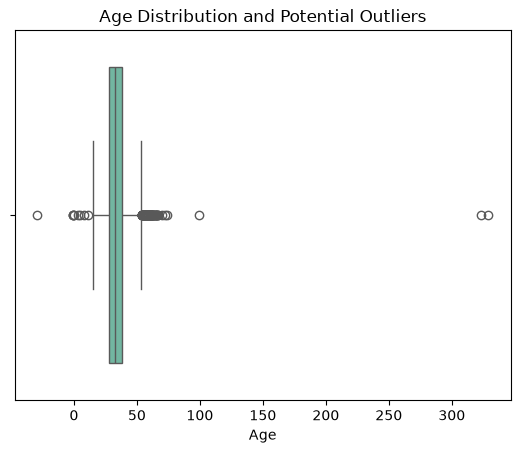

In [15]:
sns.boxplot (x=survey["Age"])
plt.title("Age Distribution and Potential Outliers")
plt.show()

The average working Age is between 18 and 70 following the government retirement . However in most cases people manage companies and businesses untill the age of 100, so it is viable to say the min should be 18 and the max 100 . 

In [16]:
# identify ages inbetween 18 and 100
survey.loc[
    (survey["Age"] < 18) | (survey["Age"] > 100),
    ["UserID", "SurveyID", "Age"]
]

,UserID,SurveyID,Age
237,3981,2019,0
2149,2069,2016,15
2301,1917,2016,3
2393,1825,2016,323
2864,1354,2016,17
3090,1128,2014,-1
3127,1091,2014,11
3228,990,2014,8
3483,735,2014,5
3502,716,2014,-1


In [17]:
# Drop those ages 
survey.drop(
    survey.loc[
        (survey["Age"] < 18) | (survey["Age"] > 100)
    ].index,
    inplace=True)


In [18]:
survey.describe()

,UserID,SurveyID,Age,self_employed,tech_company
count,4171.000000,4171.000000,4171.000000,4171.000000,4171.00000
mean,2103.572285,2016.022057,33.881323,0.147926,0.56749
std,1216.519386,1.585151,8.126580,0.367025,0.69423
min,1.000000,2014.000000,18.000000,-1.000000,-1.00000
25%,1050.500000,2014.000000,28.000000,0.000000,0.00000
50%,2102.000000,2016.000000,33.000000,0.000000,1.00000
75%,3154.500000,2017.000000,38.000000,0.000000,1.00000
max,4218.000000,2019.000000,99.000000,1.000000,1.00000


##### **Correlation**
##### Is age associated with whether respondents report a mental health condition?

<function matplotlib.pyplot.show(close=None, block=None)>

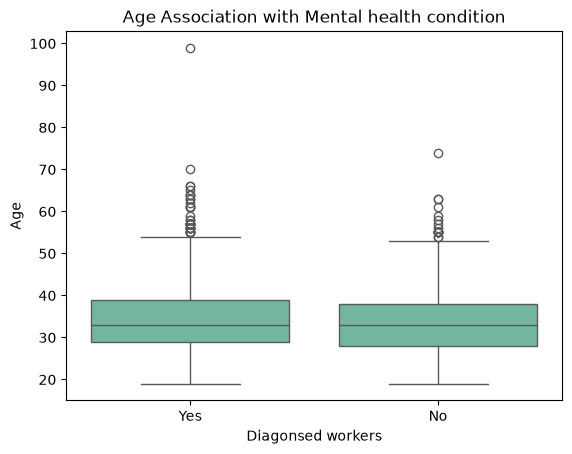

In [19]:
# Remove -1 (maybe)
Corr = survey.loc[survey[ "Diagonsed"].astype(str).str.strip()!= "-1"]

sns.boxplot ( data = Corr , x = "Diagonsed" , y = "Age" )
plt.title ("Age Association with Mental health condition"),
plt.xlabel ("Diagonsed workers")
plt.ylabel ("Age")
plt.show

In [20]:
# To calculate the correlation matrix using Pearson method convert the boolean to Binary .
survey["Diagonsed"] = survey["Diagonsed"].replace({"Yes": "1" , "No":"0"})

survey["Diagonsed"].unique()

<StringArray>
['1', '-1', '0']
Length: 3, dtype: str

In [21]:
# convert column to 
survey["Diagonsed"].astype(int)

0       1
1      -1
2      -1
3      -1
4      -1
       ..
4213   -1
4214   -1
4215   -1
4216   -1
4217   -1
Name: Diagonsed, Length: 4171, dtype: int64

In [22]:
#r_val, p_val = stats.pearsonr(survey['Age'], survey['Diagonsed'])
clean_data = survey[survey['Diagonsed'] != -1]
r_val = clean_data['Age'].corr(clean_data['Diagonsed'])
print(f'r_val:{r_val:.4f}')

r_val:0.0726


###### Pearson correlation (r) = 0.0726, indicating a very weak positive association between age and diagnosis status.

#### **Explorative Data Analysis**

##### This section higlights and showcases various relationships and data driven conclusion between the selected criteria. Questions are solved and answered to show how each of these criteria(column) affect Mental health. 

####  Age total distribution among responders?

Text(0, 0.5, 'Number of Responders')

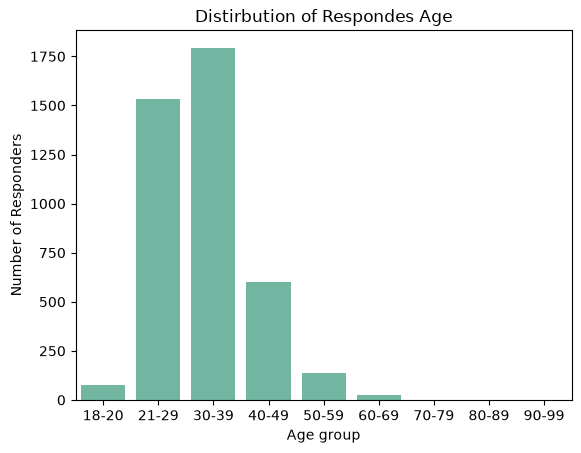

In [23]:
# creating bins to group the age of respondent 
survey['age_group']= pd.cut(survey.Age, bins = [18,21,30,40,50,60,70,80,90,100], labels = ["18-20","21-29","30-39","40-49","50-59","60-69","70-79","80-89","90-99"])

count_age_of_responders = (survey['age_group'].value_counts())
Number_of_Responders = count_age_of_responders.to_frame()

# Create Bar_plot
sns.barplot(data = Number_of_Responders ,x = 'age_group', y = 'count')
# add title 
plt.title ('Distirbution of Respondes Age')
# add X and Y label 
plt.xlabel('Age group')
plt.ylabel('Number of Responders')


###### the Age_group '30-39' has the highest number of reponders and this is because a huge number of person in this age bracket are done with Education.

#### A Map showing the Diagonised Employees across the Globe

In [24]:

#  Counting the number of "YES" Diagoneses in each country 
Cr = (
    survey.loc[
        pd.to_numeric(survey["Diagonsed"], errors="coerce") == 1,
        "Country_of_Residence"
    ]
    .value_counts()
    .sort_values(ascending=False)
)


# Importing Geo mapping file 
world = gpd.read_file("ne_10m_admin_0_countries/ne_10m_admin_0_countries.shp")

# Creating Datafram
world["ADMIN"] = world["ADMIN"].str.lower()
survey["Country_of_Residence"] = survey["Country_of_Residence"].astype(str).str.strip().str.lower()

country_counts = (
    survey["Country_of_Residence"]
    .value_counts()
    .rename_axis("ADMIN")
    .rename("responders_number")
    .reset_index()
)

merged_country = world[["ADMIN", "geometry"]].merge(country_counts, on="ADMIN", how="left")
merged_country = merged_country[merged_country["responders_number"].notna()]

print (merged_country)

         ADMIN                                           geometry  \
0    indonesia  MULTIPOLYGON (((117.70361 4.16341, 117.70361 4...   
2        chile  MULTIPOLYGON (((-69.51009 -17.50659, -69.50611...   
5    argentina  MULTIPOLYGON (((-67.1939 -22.82222, -67.14269 ...   
8        india  MULTIPOLYGON (((77.80035 35.49541, 77.81533 35...   
9        china  MULTIPOLYGON (((78.91769 33.38626, 78.91595 33...   
..         ...                                                ...   
188     taiwan  MULTIPOLYGON (((121.90577 24.9501, 121.83473 2...   
189      japan  MULTIPOLYGON (((129.78321 31.79963, 129.79086 ...   
191    iceland  MULTIPOLYGON (((-14.56363 66.38451, -14.61075 ...   
218  mauritius  MULTIPOLYGON (((57.79575 -20.22275, 57.79396 -...   
230  singapore  POLYGON ((103.96079 1.3911, 103.98569 1.38544,...   

     responders_number  
0                  2.0  
2                  3.0  
5                  4.0  
8                 49.0  
9                  2.0  
..                 ..

Text(0.5, 1.0, "Responders' Nationality")

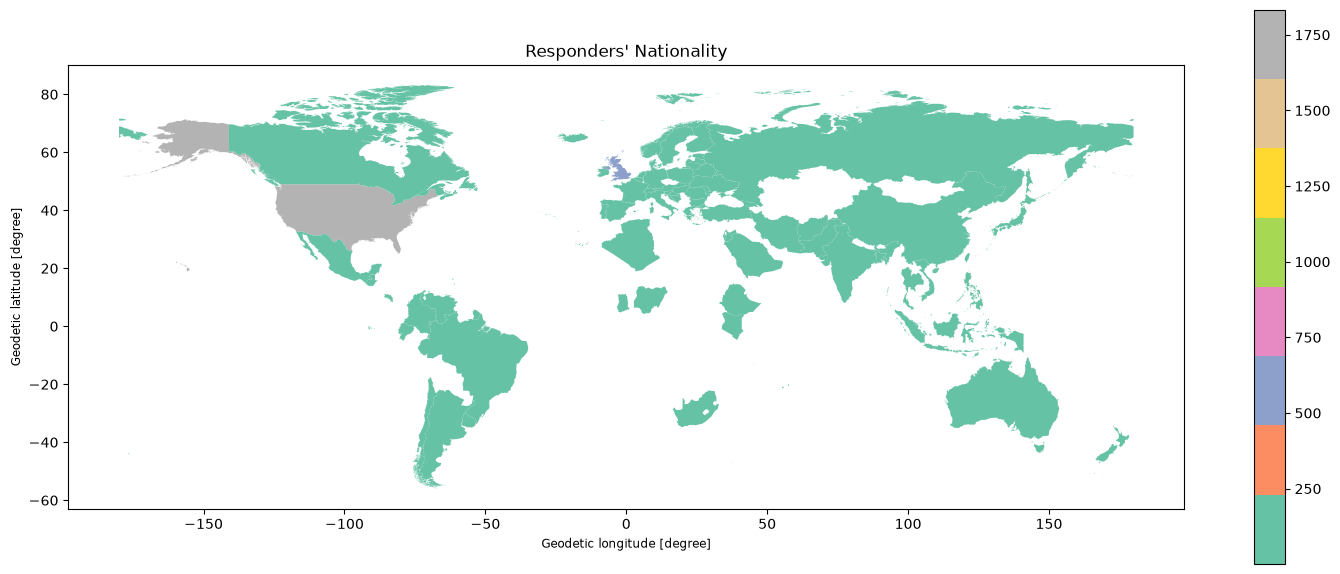

In [25]:
world = gpd.read_file(
    "ne_10m_admin_0_countries/ne_10m_admin_0_countries.shp"
)
merged = world.set_index("ADMIN").join(survey.set_index("Country_of_Residence"))

merged_country_plot = merged_country.plot(
    column="responders_number", cmap="Set2", legend=True, figsize=(18, 8)
)
merged_country_plot.set_title("Responders' Nationality")

###### The United states of America has the highest number of Diagnoses in tech roles

#### How does company size relate to the distribution of mental health conditions?

In [26]:
survey.columns

Index(['UserID', 'SurveyID', 'Age', 'Country_of_Residence',
       'Employment_country', 'self_employed', 'company_size', 'tech_company',
       'tech_role', 'Suspected_conditions', 'Diagonsed_conditions',
       'Diagonsed', 'Gender', 'age_group'],
      dtype='str')

In [27]:
survey['Diagonsed_conditions']. unique()

### creating Dictionary 


diagnosis_mapping = {
    "Anxiety & Related Disorders": [
        "Obsessive-Compulsive Disorder",
        "Anxiety Disorder (Generalized, Social, Phobia, etc)",
        "Stress Response Syndromes",
    ],

    "PTSD": [
        "Post-traumatic Stress Disorder",
        "PTSD (undiagnosed)",
    ],

    "Mood Disorders": [
        "Mood Disorder (Depression, Bipolar Disorder, etc)",
        "Depression",
        "Seasonal Affective Disorder",
    ],

    "Neurodevelopmental Disorders": [
        "Attention Deficit Hyperactivity Disorder",
        "Autism Spectrum Disorder",
        "Autism (Asperger's)",
        "Asperges",
        "PDD-NOS",
        "Pervasive Developmental Disorder (Not Otherwise Specified)",
    ],

    "Personality Disorders": [
        "Schizotypal Personality Disorder",
        "Personality Disorder (Borderline, Antisocial, Paranoid, etc)",
    ],

    "Psychotic Disorders": [
        "Psychotic Disorder (Schizophrenia, Schizoaffective, etc)",
    ],

    "Dissociative Disorders": [
        "Dissociative Disorder",
    ],

    "Addiction & Substance Disorders": [
        "Substance Use Disorder",
        "Addictive Disorder",
        "Sexual addiction",
    ],

    "Eating Disorders": [
        "Eating Disorder (Anorexia, Bulimia, etc)",
    ],

    "Other / Unclear": [
        "Transgender",
        "I haven't been formally diagnosed, so I felt uncomfortable answering, but Social Anxiety and Depression.",
        'Combination of physical impairment (strongly near-sighted) with a possibly mental one (MCD / "ADHD", though its actually a stimulus filtering impairment)',
        "Traumatic Brain Injury",
    ],

    "Unknown": [
        "unknown",
        "Unknown","-1"
    ],
}

diagnosis = {}

### create the Loop for checking in the dictioanry 

for category,responses in diagnosis_mapping.items():
    for response in responses:
        diagnosis[response] = category

### Map the new category 

survey['Diagnosis'] = survey['Diagonsed_conditions'].map(diagnosis)

# Drop rows with null values in Diagnosis

survey = survey.dropna(subset=["Diagnosis"])

# also fix the later drop line in the same cell
survey = survey.drop(columns=["Diagonsed_conditions"])


# Check the final category counts
print(survey["Diagnosis"].value_counts(dropna=False))

Diagnosis
Unknown                            3608
Mood Disorders                      301
Anxiety & Related Disorders         107
PTSD                                 45
Addiction & Substance Disorders      41
Neurodevelopmental Disorders         36
Personality Disorders                20
Psychotic Disorders                   6
Other / Unclear                       4
Eating Disorders                      1
Dissociative Disorders                1
Name: count, dtype: int64


In [28]:
# Remove the unknown variables 
filtered_survey = survey[
    (survey['Diagnosis'] != 'Unknown') &
    (survey['company_size'] != '-1')
]

Company_diagnosis = filtered_survey.value_counts(
    ['Diagnosis', 'company_size']
)

Company_diagnosis = Company_diagnosis.reset_index(name='count')

Company_diagnosis['percentage'] = (
    Company_diagnosis['count'] /
    Company_diagnosis.groupby('company_size')['count'].transform('sum')
) * 100


# create  a Pivot table to plot
heatmap_data = Company_diagnosis.pivot(
    index='Diagnosis',
    columns='company_size',
    values='percentage'
)

company_order = [
    '1-5',
    '6-25',
    '26-100',
    '100-500',
    '500-1000',
    'More than 1000'
]

heatmap_data = heatmap_data[company_order]

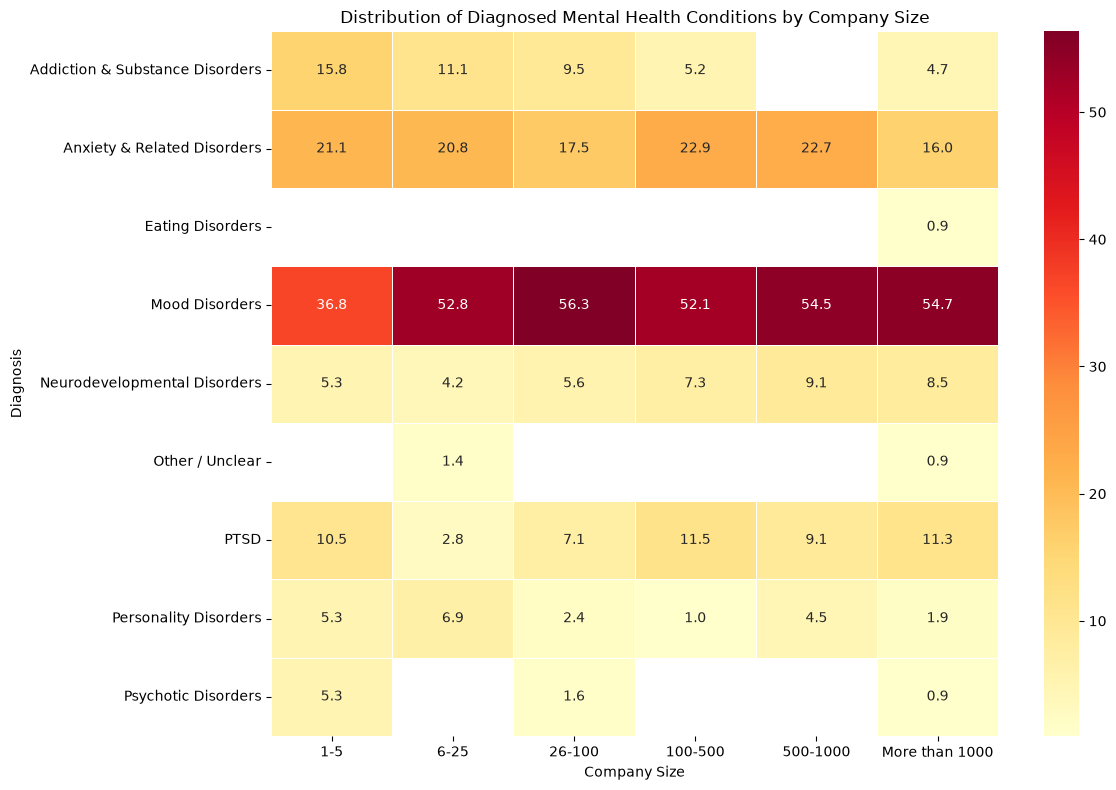

In [29]:
# Creating Heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Distribution of Diagnosed Mental Health Conditions by Company Size")
plt.xlabel("Company Size")
plt.ylabel("Diagnosis")
plt.tight_layout()
plt.show()




###### *The heatmap shows differences in the distribution of reported mental health conditions across company-size groups.*

###### *The percentages should be interpreted within each company-size group rather than as percentages of the entire dataset. Differences between groups may indicate an association between company size and the distribution of reported mental health conditions.*

###### *However, these results do not establish that company size causes differences in mental health outcomes.*

#####  What mental health condition categories are most frequently reported among respondents who provided a usable diagnosis?

In [30]:
diagnosis_counts = survey[survey['Diagnosis'] != 'Unknown']['Diagnosis'].value_counts()

Dc = diagnosis_counts.to_frame()
print (Dc)


                                 count
Diagnosis                             
Mood Disorders                     301
Anxiety & Related Disorders        107
PTSD                                45
Addiction & Substance Disorders     41
Neurodevelopmental Disorders        36
Personality Disorders               20
Psychotic Disorders                  6
Other / Unclear                      4
Eating Disorders                     1
Dissociative Disorders               1


<function matplotlib.pyplot.show(close=None, block=None)>

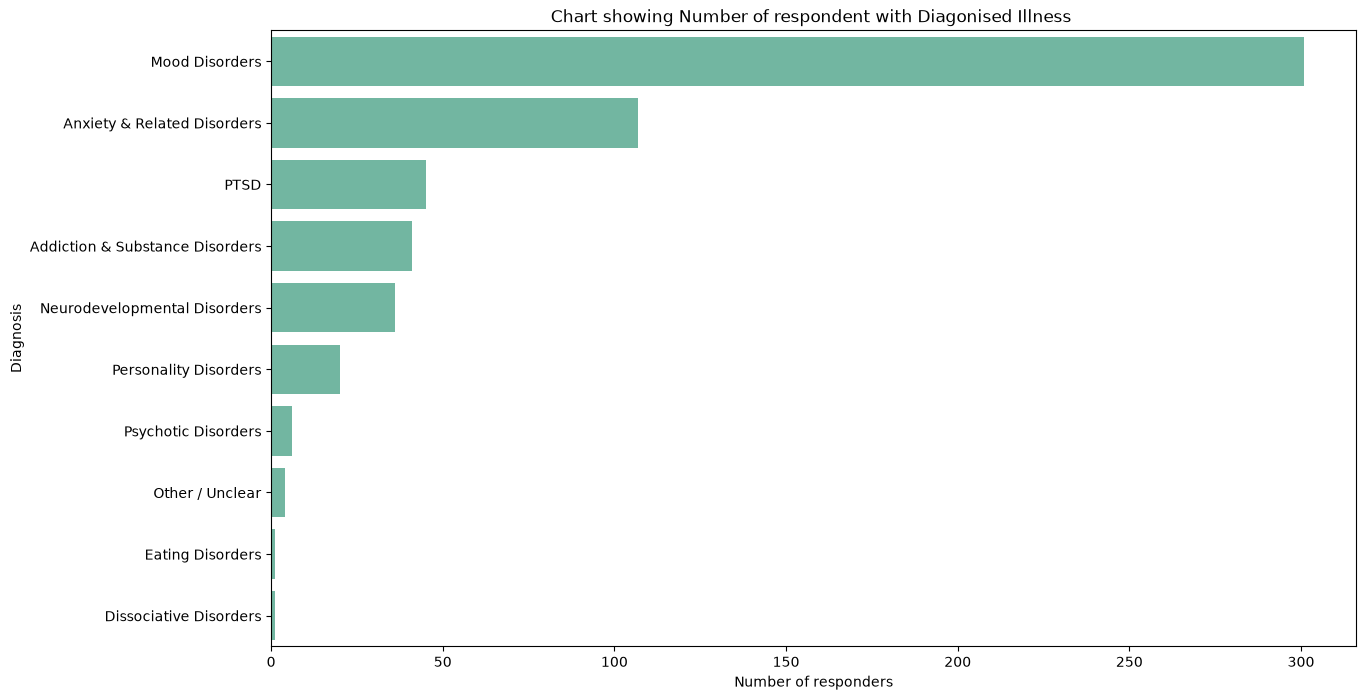

In [31]:
# Plot a Barplot
plt.figure(figsize=(14, 8))
sns.barplot(data= Dc  , y = 'Diagnosis' , x = 'count'  )


plt.xlabel('Number of responders')
plt.ylabel('Diagnosis')

plt.title ('Chart showing Number of respondent with Diagonised Illness ')

plt.show


###### *The distribution shows that some mental health condition categories are substantially more frequently reported than others. Mood disorders and anxiety-related disorders account for a large proportion of the reported conditions, while some categories have relatively few observations.*
###### *This difference in frequency should be considered when interpreting subsequent analyses, as estimates based on very small groups are less stable.*
###### *Mood disorders has the highest number of respondent with 301 .*

#### Prevalence rate  and Confidence Interval of 3 mental Illness  
 1. Mood Disorder
 2. Anxiety and Related Disorders
 3. PTSD

###### *Formula for calculating Prevalence is coined from number of people diagonised with the condition divided by the sum Population of diagonsed respondent .*
###### $$ \text{Prevalence Rate} =\frac{\text{Number of people with the condition}}{\text{Total number of people in the relevant population}}\times 100 $$

###### *Calculating Confidence Intervals For each prevalence rate, computing the confidence interval (CI). A commonly used CI is the 95% confidence interval, which can be calculated using the formula for the standard error (SE):*


 ###### $$ SE =\sqrt{\frac{p(100-p)}{n}} $$

 ###### where p = Prevalence rate 


In [32]:
# Calculate the Main Denominator to be used for each.
# since Dc was already define , we just calculate the sum of the top 3 as denominator . 
Denominators = Dc[0:3].sum()
Denominator = Denominators.iloc[0]
print (Denominator)



453


##### Prevalence rate of Mood Disorder

In [33]:
# Find Numerator for mood disorder (total count of respondent diagonised with Mood disorder)
md = survey[survey['Diagnosis'] == 'Mood Disorders']['Diagnosis'].value_counts()
Numerator_md = md.iloc[0]


Prevalence_rate_md = (Numerator_md / Denominator )*100
print("Prevalence_rate :" , Prevalence_rate)


SE_md = np.sqrt(
    (Prevalence_rate_md * (100 - Prevalence_rate_md)) / Denominator
)

CI_Lower_md = Prevalence_rate_md - (1.96 * SE_md)

CI_Upper_md = Prevalence_rate_md + (1.96 * SE_md)

print("Mood Disorders")
print("SE:", SE_md)
print("95% CI Lower:", CI_Lower_md)
print("95% CI Upper:", CI_Upper_md)

NameError: name 'Prevalence_rate' is not defined

##### Prevalence rate of Anxiety & Related Disorders

In [ ]:
# Find Numerator for Anxiety and Related Disorders (total count of respondent diagonised with Anxiety and Related Disorders)

ad = survey[survey['Diagnosis'] == 'Anxiety & Related Disorders']['Diagnosis'].value_counts()
Numerator_ad = ad.iloc[0] 


Prevalence_rate_AD = (Numerator_ad / Denominator )*100
print("Prevalence_rate :" , Prevalence_rate_AD)


SE_ad = np.sqrt(
    (Prevalence_rate_AD * (100 - Prevalence_rate_AD)) / Denominator
)

CI_Lower_ad = Prevalence_rate_AD - (1.96 * SE_ad)

CI_Upper_ad = Prevalence_rate_AD + (1.96 * SE_ad)

print("Anxiety & Related Disorders")
print("SE:", SE_ad)
print("95% CI Lower:", CI_Lower_ad)
print("95% CI Upper:", CI_Upper_ad)

Prevalence_rate : 23.62030905077263
Anxiety & Related Disorders
SE: 1.9956419988788814
95% CI Lower: 19.70885073297002
95% CI Upper: 27.531767368575238


##### Prevalence rate of PTSD

In [ ]:
# Find Numerator for PTSD (total count of respondent diagonised with PTSD)

PTsd = survey[survey['Diagnosis'] == 'PTSD']['Diagnosis'].value_counts()
Numerator_PTsd = PTsd.iloc[0] 


Prevalence_rate_for_PTSD = (Numerator_PTsd / Denominator )*100
print("Prevalence_rate :" , Prevalence_rate_for_PTSD)


SE_ptsd = np.sqrt(
    (Prevalence_rate_for_PTSD * (100 - Prevalence_rate_for_PTSD)) / Denominator
)

CI_Lower_ptsd = Prevalence_rate_for_PTSD - (1.96 * SE_ptsd)

CI_Upper_ptsd = Prevalence_rate_for_PTSD + (1.96 * SE_ptsd)

print("PTSD")
print("SE:", SE_ptsd)
print("95% CI Lower:", CI_Lower_ptsd)
print("95% CI Upper:", CI_Upper_ptsd)

Prevalence_rate : 9.933774834437086
PTSD
SE: 1.4053646828469137
95% CI Lower: 7.179260056057135
95% CI Upper: 12.688289612817037


In [ ]:
# Create a table containing the three mental illnesses
# Create a table containing the three mental illnesses
# Using the already-computed diagnosis counts to avoid undefined variables.
diag_names = ["Mood Disorders", "Anxiety & Related Disorders", "PTSD"]

# Denominator = total count across the three main diagnoses
denominator = Dc.loc[diag_names, "count"].sum()

rows = []
for illness in diag_names:
    count = Dc.loc[illness, "count"]
    prevalence_rate = (count / denominator) * 100
    se = np.sqrt((prevalence_rate * (100 - prevalence_rate)) / denominator)
    ci_lower = prevalence_rate - (1.96 * se)
    ci_upper = prevalence_rate + (1.96 * se)

    rows.append({
        "Mental_Illness": illness,
        "prevalence_rate": prevalence_rate,
        "CI_Lower": ci_lower,
        "CI_Upper": ci_upper
    })

illness_prevalence = pd.DataFrame(rows)
illness_prevalence

illness_prevalence

NameError: name 'Prevalence_rate_AD' is not defined

In [ ]:
print(type(prevalence_rate))

NameError: name 'prevalence_rate' is not defined

In [ ]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x="Mental_Illness",
    y="prevalence_rate",
    data=illness_prevalence
)

plt.errorbar(
    x=range(len(illness_prevalence)),
    y=illness_prevalence["prevalence_rate"].to_numpy(),
    yerr=[
        illness_prevalence["prevalence_rate"].to_numpy()
        - illness_prevalence["CI_Lower"].to_numpy(),
        illness_prevalence["CI_Upper"].to_numpy()
        - illness_prevalence["prevalence_rate"].to_numpy()
    ],
    fmt="none",
    capsize=5
)

ax.set_title("Prevalence of Mental Illnesses with 95% Confidence Intervals")
ax.set_xlabel("Mental Illness")
ax.set_ylabel("Prevalence Rate (%)")

plt.show()

NameError: name 'illness_prevalence' is not defined

<Figure size 1200x600 with 0 Axes>

In [ ]:

print(illness_prevalence.columns.tolist())

NameError: name 'illness_prevalence' is not defined